In [1]:
import pandas as pd
import numpy as np
import gzip
import matplotlib.pyplot as plt
import pickle
from scipy.stats import linregress
import os
import sys
from datetime import date
from sklearn.metrics import auc, f1_score
import random
from sklearn.decomposition import NMF, non_negative_factorization
import seaborn as sns
import time
from matplotlib.colors import LogNorm, Normalize
from mpl_toolkits.axes_grid1 import axes_grid

In [2]:
#load npz file
mixture_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Mixture.npy.gz', "r")
mixture_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    mixture_all_cycles.append(cycle_np_file['new_decomp_mixture'])

mixture_all_cycles = np.array(mixture_all_cycles)

1


In [3]:
#load npz file
basis_all_cycles = []

#original mixture
fn = gzip.GzipFile('/home/ctrader/Hold/DHS/2018-06-08NC16_NNDSVD_Basis.npy.gz', "r")
basis_all_cycles.append(np.float32(np.load(fn)))

for i in range(1, 2):
    print(i)
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_booldhsarr_basis_mixture_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    basis_all_cycles.append(cycle_np_file['new_decomp_basis'])

basis_all_cycles = np.array(basis_all_cycles)

1


In [3]:
n_components, n_DHSs = mixture_all_cycles[0].shape

In [6]:
mixture_all_cycles.shape

(2, 16, 3591898)

In [6]:
DHS_metadata = pd.read_table('/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_hg38_WM20190703.txt.gz', header=None)

col_names = DHS_metadata.iloc[0]
DHS_metadata = DHS_metadata[1:]
DHS_metadata.columns = col_names
DHS_metadata = DHS_metadata.reset_index()
DHS_metadata[['identifier']] = DHS_metadata[['identifier']].astype(str)
DHS_metadata = DHS_metadata.drop(columns=['index'])
DHS_metadata['mean_signal'] = DHS_metadata['mean_signal'].astype(float)

#top 10%
DHS_metadata['ind'] = DHS_metadata.index
DHS_metadata_sortby_mean_signal = DHS_metadata.sort_values(['mean_signal'], ascending=False)
top_10_percent_DHSs = DHS_metadata_sortby_mean_signal.iloc[:int(np.round(n_DHSs/10))]
top_10_percent_DHSs_inds = np.array(top_10_percent_DHSs['ind'])
top_10_percent_DHSs_identifiers = np.array(top_10_percent_DHSs['identifier'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (1,2,3,4,5,6,7,8) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [7]:
#loading biosample metadata
tsv_file = open("/home/ctrader/Hold/DHS/DHS_Index_and_Vocabulary_metadata.tsv")
biosample_df = pd.read_csv(tsv_file, delimiter="\t")

In [9]:
#load npz file
added_recon_all_cycles = []
removed_recon_all_cycles = []
added_flat_inds_all_cycles = []
removed_flat_inds_all_cycles = []

for i in range(1, 2):
    filename = '/home/ctrader/Hold/NMF/DHS/fill_in_multiple_at_a_time_saves/reconstructed_threshold_flip_added_removed_recon_flatinds_to0thresh0.0_to1thresh1.0_cycle'+str(i)+'_CT20220323.npz'
    cycle_np_file = np.load(filename)
    added_recon_all_cycles.append(cycle_np_file['added_recon'])
    removed_recon_all_cycles.append(cycle_np_file['removed_recon'])
    added_flat_inds_all_cycles.append(cycle_np_file['added_flat_inds'])
    removed_flat_inds_all_cycles.append(cycle_np_file['removed_flat_inds'])

In [8]:
#The component number for the summary data corresponds to the NMF component
comp0 = pd.read_table('/home/ctrader/lightfm_data/comp1_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp0 mean'])
comp1 = pd.read_table('/home/ctrader/lightfm_data/comp2_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp1 mean'])
comp2 = pd.read_table('/home/ctrader/lightfm_data/comp3_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp2 mean'])
comp3 = pd.read_table('/home/ctrader/lightfm_data/comp4_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp3 mean'])
comp4 = pd.read_table('/home/ctrader/lightfm_data/comp5_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp4 mean'])
comp5 = pd.read_table('/home/ctrader/lightfm_data/comp6_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp5 mean'])
comp6 = pd.read_table('/home/ctrader/lightfm_data/comp7_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp6 mean'])
comp7 = pd.read_table('/home/ctrader/lightfm_data/comp8_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp7 mean'])
comp8 = pd.read_table('/home/ctrader/lightfm_data/comp9_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp8 mean'])
comp9 = pd.read_table('/home/ctrader/lightfm_data/comp10_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp9 mean'])
comp10 = pd.read_table('/home/ctrader/lightfm_data/comp11_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp10 mean'])
comp11 = pd.read_table('/home/ctrader/lightfm_data/comp12_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp11 mean'])
comp12 = pd.read_table('/home/ctrader/lightfm_data/comp13_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp12 mean'])
comp13 = pd.read_table('/home/ctrader/lightfm_data/comp14_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp13 mean'])
comp14 = pd.read_table('/home/ctrader/lightfm_data/comp15_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp14 mean'])
comp15 = pd.read_table('/home/ctrader/lightfm_data/comp16_average_DHS_signal_CT20220106.txt', names=['name', 'size', 'covered', 'sum', 'mean0', 'comp15 mean'])

/home/ctrader/.conda/envs/lightfm/lib/python3.8/site-packages/IPython/core/interactiveshell.py:3441: DtypeWarning: Columns (0) have mixed types.Specify dtype option on import or set low_memory=False.
  exec(code_obj, self.user_global_ns, self.user_ns)


In [9]:
all_comps_average_signal = comp0[['name', 'comp0 mean']].merge(comp1[['name', 'comp1 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp2[['name', 'comp2 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp3[['name', 'comp3 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp4[['name', 'comp4 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp5[['name', 'comp5 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp6[['name', 'comp6 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp7[['name', 'comp7 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp8[['name', 'comp8 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp9[['name', 'comp9 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp10[['name', 'comp10 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp11[['name', 'comp11 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp12[['name', 'comp12 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp13[['name', 'comp13 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp14[['name', 'comp14 mean']], how='inner', on='name')
all_comps_average_signal = all_comps_average_signal.merge(comp15[['name', 'comp15 mean']], how='inner', on='name')
all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)
# all_comps_average_signal['average over all comps'] = (all_comps_average_signal['comp0 mean'] + all_comps_average_signal['comp1 mean'] + all_comps_average_signal['comp2 mean'] + all_comps_average_signal['comp3 mean'] + all_comps_average_signal['comp4 mean'] + all_comps_average_signal['comp5 mean'] + all_comps_average_signal['comp6 mean'] + all_comps_average_signal['comp7 mean'] + all_comps_average_signal['comp8 mean'] + all_comps_average_signal['comp9 mean'] + all_comps_average_signal['comp10 mean'] + all_comps_average_signal['comp11 mean'] + all_comps_average_signal['comp12 mean'] + all_comps_average_signal['comp13 mean'] + all_comps_average_signal['comp14 mean'] + all_comps_average_signal['comp15 mean'])/16
all_comps_average_signal['name'] = all_comps_average_signal['name'].astype(str)
all_comps_average_signal = all_comps_average_signal.set_index(['name'])
# old_columns = list(all_comps_average_signal.columns).extend(['max signal'])
# all_comps_average_signal.columns = [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15]
all_comps_average_signal['max signal'] = all_comps_average_signal.idxmax(axis=1)
# all_comps_average_signal.columns = old_columns

DHS_metadata_identifiers = np.array(DHS_metadata['identifier'])

all_comps_average_signal = all_comps_average_signal.loc[DHS_metadata_identifiers]
top_10_percent_T_F = np.array([False]*len(all_comps_average_signal))
top_10_percent_T_F[top_10_percent_DHSs_inds] = True
all_comps_average_signal['top 10 percent'] = top_10_percent_T_F
all_comps_average_signal

/tmp/ipykernel_89693/4162047146.py:16: FutureWarning: Dropping of nuisance columns in DataFrame reductions (with 'numeric_only=None') is deprecated; in a future version this will raise TypeError.  Select only valid columns before calling the reduction.
  all_comps_average_signal['average over all comps'] = all_comps_average_signal.mean(axis=1)


,comp0 mean,comp1 mean,comp2 mean,comp3 mean,comp4 mean,comp5 mean,comp6 mean,comp7 mean,comp8 mean,comp9 mean,comp10 mean,comp11 mean,comp12 mean,comp13 mean,comp14 mean,comp15 mean,average over all comps,max signal,top 10 percent
name,,,,,,,,,,,,,,,,,,,
1.10011,0.053318,0.046712,0.039907,0.034054,0.029935,0.019642,0.050381,0.044771,0.038645,0.052703,0.028230,0.073723,0.043809,0.059390,0.188392,0.038370,0.052624,comp14 mean,False
1.10021,0.012199,0.006616,0.009675,0.005551,0.009631,0.015424,0.037962,0.003689,0.003913,0.006651,0.014848,0.009479,0.012386,0.008923,0.008113,0.004985,0.010628,comp6 mean,False
1.10025,0.013972,0.010649,0.002742,0.005082,0.004388,0.004117,0.010228,0.085321,0.003772,0.005397,0.006319,0.011102,0.003377,0.002977,0.005027,0.015383,0.011866,comp7 mean,False
1.10027,0.002374,0.003701,0.025612,0.018267,0.005331,0.021985,0.032393,0.008670,0.010130,0.010930,0.006678,0.003414,0.000000,0.005247,0.015185,0.002535,0.010778,comp6 mean,False
1.1003,0.017845,0.008636,0.009204,0.007383,0.013745,0.008851,0.032531,0.006222,0.006340,0.007592,0.031536,0.004111,0.014399,0.013492,0.006270,0.012739,0.012556,comp6 mean,False
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
Y.994281,0.016663,0.013051,0.006976,0.008886,0.013321,0.019894,0.044953,0.010084,0.012202,0.006862,0.017083,0.012507,0.017318,0.012432,0.019537,0.017870,0.015602,comp6 mean,False
Y.994286,0.003373,0.007940,0.003355,0.002987,0.008398,0.005565,0.007886,0.005332,0.002115,0.004837,0.001810,0.005148,0.001989,0.004099,0.007139,0.003393,0.004710,comp4 mean,False
Y.994292,0.034594,0.021025,0.013023,0.017206,0.024326,0.086499,0.231924,0.011905,0.017295,0.018428,0.025081,0.018944,0.029714,0.030595,0.021135,0.143163,0.046554,comp6 mean,False


**Removed Biosamples**

In [10]:
all_0_biosample_inds = np.where(np.sum(basis_all_cycles, axis=2)==0)

all_0_biosample_inds_cycle1 = all_0_biosample_inds[1][all_0_biosample_inds[0]==1]

In [12]:
#finding removed biosample_inds
removed_biosample_inds_all_cycles = []
for i in range(1):
    removed_biosample_inds_all_cycles.append(removed_flat_inds_all_cycles[i]  // n_DHSs)
    
#finding removed biosample_inds
added_biosample_inds_all_cycles = []
for i in range(1):
    added_biosample_inds_all_cycles.append(added_flat_inds_all_cycles[i]  // n_DHSs)

In [13]:
#finding the change in call numbers for all biosamples
biosamples = np.arange(733)
all_biosample_net_count = []
for b in biosamples:
    biosample_net_count = []
    biosample_net_count.append(biosample_df.loc[b]['DHSs in Index'])
    for i in range(1):
        removed = len(removed_biosample_inds_all_cycles[i][removed_biosample_inds_all_cycles[i]==b])
        added = len(added_biosample_inds_all_cycles[i][added_biosample_inds_all_cycles[i]==b])
        biosample_net_count.append(biosample_net_count[i]+added-removed)
    all_biosample_net_count.append(biosample_net_count)
all_biosample_net_count = np.array(all_biosample_net_count)

In [14]:
biosample_df.loc[all_0_biosample_inds_cycle1]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index


In [15]:
np.mean(np.array(biosample_df['DCC SPOT score']))

0.5001987721691677

**How does mean DHS signal change after DHSs are removed each cycle** 

In [16]:
not_0_dhs_inds = np.where(np.sum(mixture_all_cycles, axis=1)!=0)

not_0_dhs_inds_cycle1 = not_0_dhs_inds[1][not_0_dhs_inds[0]==1]

In [17]:
print(len(not_0_dhs_inds_cycle1))

3591898


In [18]:
print(np.mean(DHS_metadata['mean_signal']))
print(np.mean(DHS_metadata.loc[not_0_dhs_inds_cycle1]['mean_signal']))

0.6401371981706325
0.6401371981706325


**Top 10% DHSs for each Mixture**

In [19]:
#quantitatively comparing mixture embeddings
mixture_all_cycles_10per = mixture_all_cycles[:, :, top_10_percent_DHSs_inds]

**Top comp of basis and top 10% mixtures**

In [20]:
#top comps
mixture_all_cycles_10per_top_comp = np.argmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_top_comp_val = np.max(mixture_all_cycles_10per, axis=1)

#sum
mixture_all_cycles_10per_sum = np.sum(mixture_all_cycles_10per, axis=1)

In [21]:
mixture_all_cycles_10per_top_comp_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                     np.nan, 
                                                     mixture_all_cycles_10per_top_comp)

mixture_all_cycles_10per_top_comp_val_notall0 = np.where(mixture_all_cycles_10per_sum==0, 
                                                         np.nan, 
                                                         mixture_all_cycles_10per_top_comp_val)

mixture_all_cycles_10per[np.where(mixture_all_cycles_10per_sum==0)[0],
                         :, 
                         np.where(mixture_all_cycles_10per_sum==0)[1]]=np.nan

In [22]:
#top comps
basis_all_cycles_top_comp = np.argmax(basis_all_cycles, axis=2)
basis_all_cycles_top_comp_val = np.max(basis_all_cycles, axis=2)

#sum
basis_all_cycles_sum = np.sum(basis_all_cycles, axis=2)

In [23]:
basis_all_cycles_top_comp_notall0 = np.where(basis_all_cycles_sum==0, 
                                             np.nan, 
                                             basis_all_cycles_top_comp)

basis_all_cycles_top_comp_val_notall0 = np.where(basis_all_cycles_sum==0, 
                                                 np.nan, 
                                                 basis_all_cycles_top_comp_val)

basis_all_cycles[np.where(basis_all_cycles_sum==0)[0],
                 np.where(basis_all_cycles_sum==0)[1],
                 :]=np.nan

**Mixture (top 10%) and Basis Purity**

In [24]:
#top 10% DHSs
mixture_all_cycles_10per_top_comp_val = np.nanmax(mixture_all_cycles_10per, axis=1)
mixture_all_cycles_10per_nansum = np.nansum(mixture_all_cycles_10per, axis=1)

mixture_all_cycles_10per_pur_by_sum = mixture_all_cycles_10per_top_comp_val / mixture_all_cycles_10per_nansum

In [25]:
basis_all_cycles_top_comp_val = np.nanmax(basis_all_cycles, axis=2)
basis_all_cycles_nansum = np.nansum(basis_all_cycles, axis=2)

basis_all_cycles_pur_by_sum = basis_all_cycles_top_comp_val / basis_all_cycles_nansum

Text(0.5, 1.07, 'NMF Loading Purity (by Top Component Value/Sum of Components)\nReconstruction Threshold Flip, Threshold=0.0/1.0')

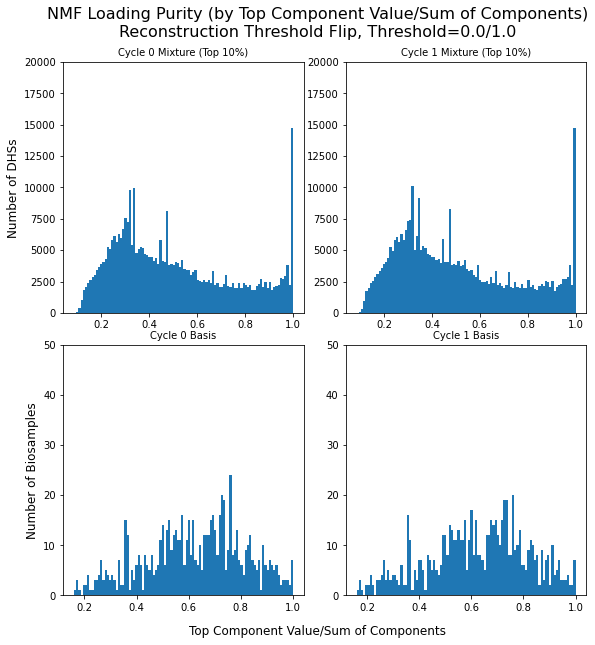

In [26]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_all_cycles_10per_pur_by_sum[ind], bins=100)
    axes[ind+2].hist(basis_all_cycles_pur_by_sum[ind], bins=100)
    axes[ind].set_ylim([0, 20000])#70000
    axes[ind+2].set_ylim([0, 50])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Top Component Value/Sum of Components', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Top Component Value/Sum of Components)\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

In [27]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
basis_purity_count_all_cycles = []
for cycle in range(2):
    count_per_cycle = []
    for biosample in range(len(basis_all_cycles[0, :, 0])):
        loading_sum = basis_all_cycles_nansum[cycle, biosample]
        loading = basis_all_cycles[cycle, biosample, :]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    basis_purity_count_all_cycles.append(count_per_cycle)
basis_purity_count_all_cycles = np.array(basis_purity_count_all_cycles)

In [28]:
#finding the number of comps it takes to make up 50% of loading sum
threshold = 0.5
mixture_purity_count_all_cycles_10per = []
for cycle in range(2):
    count_per_cycle = []
    for dhs in range(len(mixture_all_cycles_10per[0, 0, :])):
        loading_sum = mixture_all_cycles_10per_nansum[cycle, dhs]
        loading = mixture_all_cycles_10per[cycle, :, dhs]
        loading_sorted = -np.sort(-loading)
        count = 0
        running_sum = 0
        while running_sum < (threshold * loading_sum):
            running_sum += loading_sorted[count]
            count += 1
        count_per_cycle.append(count)
    mixture_purity_count_all_cycles_10per.append(count_per_cycle)
mixture_purity_count_all_cycles_10per = np.array(mixture_purity_count_all_cycles_10per)

Text(0.5, 1.07, 'NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nReconstruction Threshold Flip, Threshold=0.0/1.0')

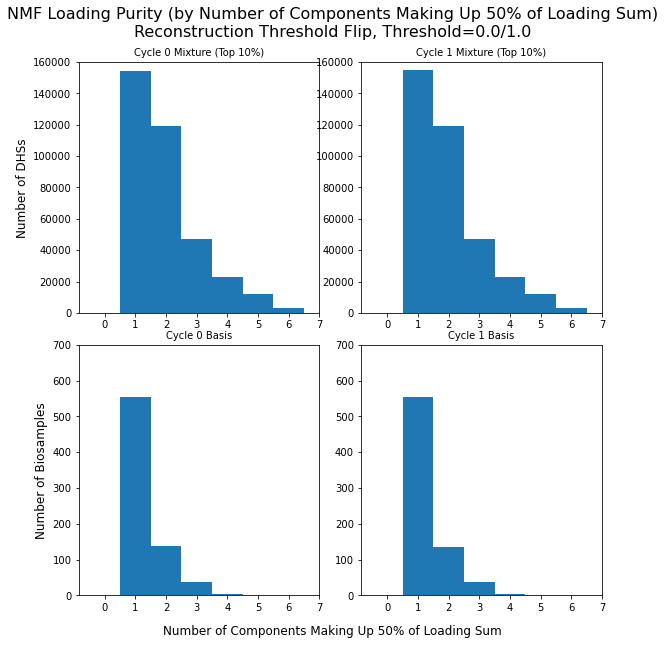

In [29]:
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(8,8))
fig.patch.set_facecolor('white')
fig.tight_layout()

axes = axes.ravel()
for ind in range(2):
    axes[ind].hist(mixture_purity_count_all_cycles_10per[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].hist(basis_purity_count_all_cycles[ind], width=1, align='left', bins=[0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind].set_ylim([0, 160000])#70000
    axes[ind+2].set_ylim([0, 700])#500
    axes[ind].set_title('Cycle '+str(ind)+' Mixture (Top 10%)', fontsize=10)
    axes[ind+2].set_title('Cycle %s Basis' %(ind), fontsize=10)
    axes[ind].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
    axes[ind+2].set_xticks([0, 1, 2, 3, 4, 5, 6, 7])
#     axes[ind].set_xlim([0, 7])
#     axes[ind+4].set_xlim([0, 7])

axes[0].set_ylabel('Number of DHSs', fontsize=12)
axes[2].set_ylabel('Number of Biosamples', fontsize=12)
fig.text(0.5, -0.02, 'Number of Components Making Up 50% of Loading Sum', ha='center', fontsize=12)
plt.suptitle('NMF Loading Purity (by Number of Components Making Up 50% of Loading Sum)\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16, x=0.5, y=1.07)

**Heatmaps (of just DHSs that change component)**

In [30]:
heatmap_mixture_all_cycles_10per_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs, val1, val0 in zip(mixture_all_cycles_10per_top_comp_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_notall0[i], 
                                             range(len(mixture_all_cycles_10per_top_comp_notall0[0])),
                                             mixture_all_cycles_10per_top_comp_val_notall0[i+1], 
                                             mixture_all_cycles_10per_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_10per_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))
    changed_dhss_original_comp_val.append(np.array(original_comp_val))
    changed_dhss_new_comp_val.append(np.array(new_comp_val))

changed_all_dhss_all_cycles = []
for i in changed_dhss_all_cycles:
    changed_all_dhss_all_cycles.append(top_10_percent_DHSs_inds[i])

In [31]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)
    
changed_dhss_original_comp_val_arr = []
for i in changed_dhss_original_comp_val:
    changed_dhss_original_comp_val_arr.extend(i)
changed_dhss_original_comp_val_arr = np.array(changed_dhss_original_comp_val_arr)
    
changed_dhss_new_comp_val_arr = []
for i in changed_dhss_new_comp_val:
    changed_dhss_new_comp_val_arr.extend(i)
changed_dhss_new_comp_val_arr = np.array(changed_dhss_new_comp_val_arr)

In [32]:
heatmap_mixture_all_cycles_10per_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison, axis=0)

In [33]:
np.sum(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum)

1279

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

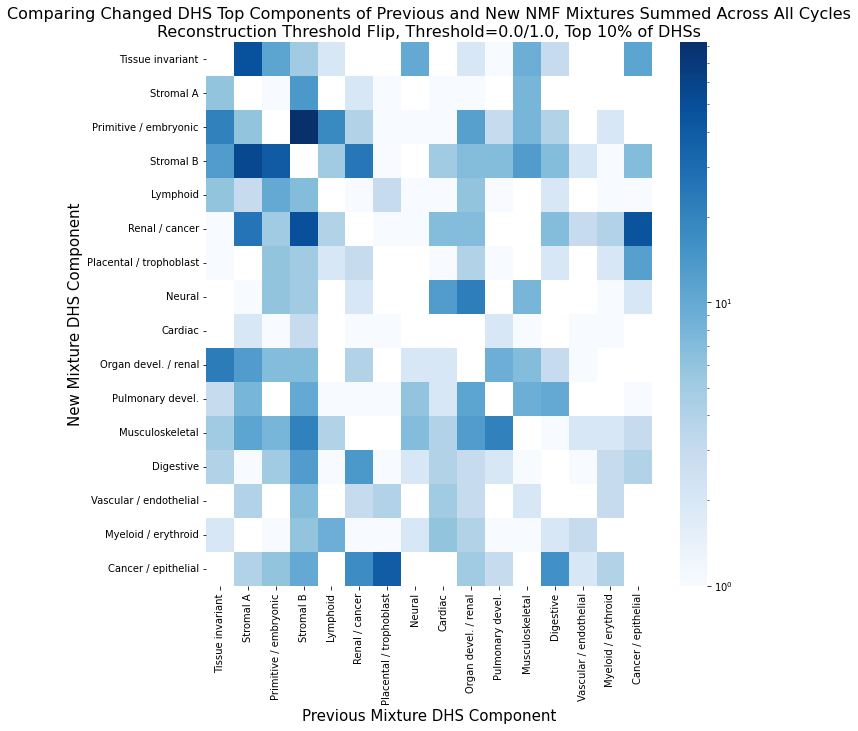

In [34]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_10per_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Previous Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Mixtures Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16)

In [35]:
heatmap_basis_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_biosamples_all_cycles = []
changed_biosamples_original_comp = []
changed_biosamples_new_comp = []
changed_biosamples_original_comp_val = []
changed_biosamples_new_comp_val = []

for i in range(1):
    changed_biosamples_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, biosample, val1, val0 in zip(basis_all_cycles_top_comp_notall0[i+1], 
                                             basis_all_cycles_top_comp_notall0[i], 
                                             range(len(basis_all_cycles_top_comp_notall0[0])),
                                             basis_all_cycles_top_comp_val_notall0[i+1], 
                                             basis_all_cycles_top_comp_val_notall0[i],):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
#             print(biosample)
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
#             print(comp0, comp1, val0, val1)
            heatmap_basis_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            changed_biosamples_1_cycle.append(biosample)
            original_comp.append(comp0)
            new_comp.append(comp1)
            original_comp_val.append(val0)
            new_comp_val.append(val1)
            
    changed_biosamples_all_cycles.append(np.array(changed_biosamples_1_cycle))
    changed_biosamples_original_comp.append(np.array(original_comp))
    changed_biosamples_new_comp.append(np.array(new_comp))
    changed_biosamples_original_comp_val.append(np.array(original_comp_val))
    changed_biosamples_new_comp_val.append(np.array(new_comp_val))

In [36]:
changed_biosamples_all_cycles_arr = []
for i in changed_biosamples_all_cycles:
    changed_biosamples_all_cycles_arr.extend(i)
changed_biosamples_all_cycles_arr = np.array(changed_biosamples_all_cycles_arr)
    
changed_biosamples_original_comp_arr = []
for i in changed_biosamples_original_comp:
    changed_biosamples_original_comp_arr.extend(i)
changed_biosamples_original_comp_arr = np.array(changed_biosamples_original_comp_arr)
    
changed_biosamples_new_comp_arr = []
for i in changed_biosamples_new_comp:
    changed_biosamples_new_comp_arr.extend(i)
changed_biosamples_new_comp_arr = np.array(changed_biosamples_new_comp_arr)
    
changed_biosamples_original_comp_val_arr = []
for i in changed_biosamples_original_comp_val:
    changed_biosamples_original_comp_val_arr.extend(i)
changed_biosamples_original_comp_val_arr = np.array(changed_biosamples_original_comp_val_arr)
    
changed_biosamples_new_comp_val_arr = []
for i in changed_biosamples_new_comp_val:
    changed_biosamples_new_comp_val_arr.extend(i)
changed_biosamples_new_comp_val_arr = np.array(changed_biosamples_new_comp_val_arr)

In [37]:
heatmap_basis_all_cycles_top_comp_comparison_sum = np.sum(heatmap_basis_all_cycles_top_comp_comparison, axis=0)

In [38]:
np.sum(heatmap_basis_all_cycles_top_comp_comparison_sum)

5

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

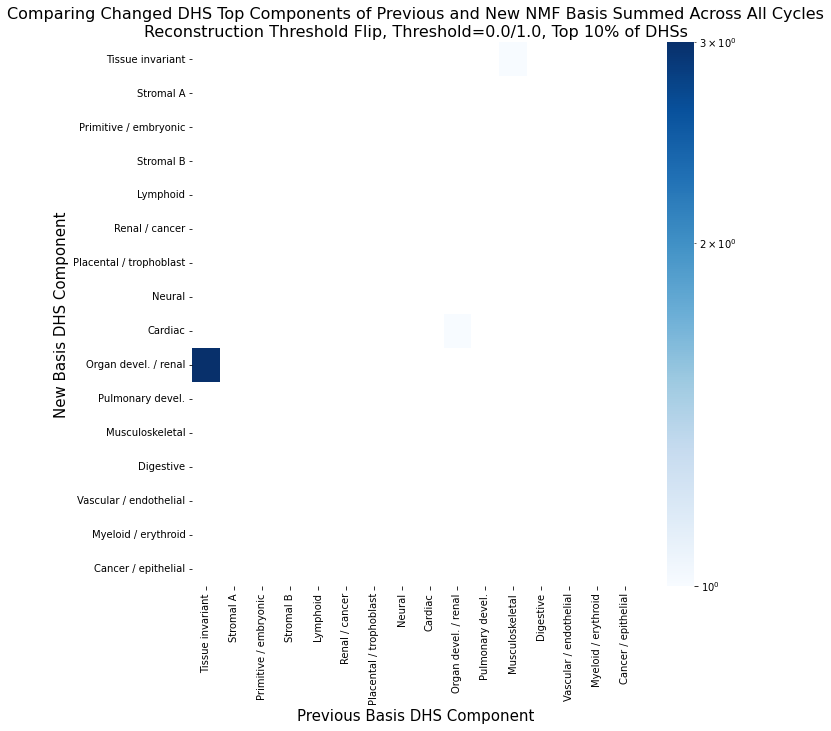

In [39]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_basis_all_cycles_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Basis DHS Component', fontsize=15)
ax.set_xlabel('Previous Basis DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Previous and New NMF Basis Summed Across All Cycles\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16)

**Top 15 Biosamples of each component**

In [40]:
changed__biosamples_all_cycles = []
changed__biosamples_original_comp_all_cycles = []
changed__biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed__biosamples_1_cycle = []
    changed__biosamples_original_comp_1_cycle = []
    changed__biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        
        print(str(changed_biosample) + ',', 
              biosample_df.loc[changed_biosample]['Biosample name'] + ',', 
              comps_for_heatmap[old_comp] + ' ->', 
              comps_for_heatmap[new_comp] + ',',
              'SPOT = ' + str(biosample_df.loc[changed_biosample]['DCC SPOT score']))
        changed__biosamples_1_cycle.append(changed_biosample)
        changed__biosamples_original_comp_1_cycle.append(old_comp)
        changed__biosamples_new_comp_1_cycle.append(new_comp)
            
    changed__biosamples_all_cycles.append(np.array(changed__biosamples_1_cycle))
    changed__biosamples_original_comp_all_cycles.append(np.array(changed__biosamples_original_comp_1_cycle))
    changed__biosamples_new_comp_all_cycles.append(np.array(changed__biosamples_new_comp_1_cycle))

0
411, fKidney_renal_cortex_R, Tissue invariant -> Organ devel. / renal, SPOT = 0.5307
486, fKidney_R, Tissue invariant -> Organ devel. / renal, SPOT = 0.5321
531, fKidney, Tissue invariant -> Organ devel. / renal, SPOT = 0.438
719, fBone_arm_left, Musculoskeletal -> Tissue invariant, SPOT = 0.4059
728, fUmbilical_cord, Organ devel. / renal -> Cardiac, SPOT = 0.5652


In [41]:
top_15_biosample_inds = np.array(biosample_df[~biosample_df['Vocabulary representative'].isnull()].index)

In [42]:
changed_top15biosamples_all_cycles = []
changed_top15biosamples_original_comp_all_cycles = []
changed_top15biosamples_new_comp_all_cycles = []
for i in range(1):
    print(i)
    changed_top15biosamples_1_cycle = []
    changed_top15biosamples_original_comp_1_cycle = []
    changed_top15biosamples_new_comp_1_cycle = []
    for changed_biosample, old_comp, new_comp in zip(changed_biosamples_all_cycles[i], 
                                                     changed_biosamples_original_comp[i], 
                                                     changed_biosamples_new_comp[i]):
        
        if changed_biosample in top_15_biosample_inds:
            print(changed_biosample, biosample_df.loc[changed_biosample]['Biosample name'], comps_for_heatmap[old_comp], comps_for_heatmap[new_comp])
            changed_top15biosamples_1_cycle.append(changed_biosample)
            changed_top15biosamples_original_comp_1_cycle.append(old_comp)
            changed_top15biosamples_new_comp_1_cycle.append(new_comp)
            
    changed_top15biosamples_all_cycles.append(np.array(changed_top15biosamples_1_cycle))
    changed_top15biosamples_original_comp_all_cycles.append(np.array(changed_top15biosamples_original_comp_1_cycle))
    changed_top15biosamples_new_comp_all_cycles.append(np.array(changed_top15biosamples_new_comp_1_cycle))

0
486 fKidney_R Tissue invariant Organ devel. / renal
531 fKidney Tissue invariant Organ devel. / renal


In [43]:
biosample_df.loc[changed_top15biosamples_all_cycles[0]]

,library order,Biosample name,Vocabulary representative,DCC Experiment ID,DCC Library ID,DCC Biosample ID,Altius Aggregation ID,Altius Library ID,Altius Biosample ID,Replicate indicators,...,Library cleanup,DNaseI units/mL,Amount Nucleic Acid (ng),Nuclei count,Protease inhibitor,Library sequencing date,Reads used,DCC SPOT score,Per-biosample peaks,DHSs in Index
486,487,fKidney_R,Tissue invariant,ENCSR017TFH,ENCLB521YRN,ENCBS278PUM,AG8854,LN4936,DS20951,NaN,...,minElute,60.0,19.6,7830000.0,A+Sucrose,2011-11-15,25040896,0.5321,46710,46484
531,532,fKidney,Tissue invariant,ENCSR645GJD,ENCLB963LDG,ENCBS382CRI,AG8810,LN10157,DS20988,DS20987,...,Sucrose,70.0,32.98,18120000.0,A+Sucrose,2011-11-18,36520939,0.4380,52222,51894


**DHSs that change component**

In [18]:
convex_hull_outliers = []
f = open("/home/ajoshi/similarity_metrics/results/convex_hull_PC_vertices", "r")
for line in f:
    convex_hull_outliers.append(int(line.strip('\n')))
convex_hull_outliers = np.array(convex_hull_outliers)

In [10]:
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']
color = ['#FFE500', '#FE8102', '#FF0000', '#07AF00', '#4C7D14', '#414613', '#05C1D9', '#0467FD', '#009588', '#BB2DD4', '#7A00FF', '#4A6876', '#08245B', '#B9461D', '#692108', '#C3C3C3']
neworder = np.array([16,10,7,11,2,12,1,8,4,15,14,5,9,6,3,13]).astype(int) - 1
color = np.array(color)[neworder]

In [4]:
mixture_all_cycles_top_comp = np.argmax(mixture_all_cycles, axis=1)

In [7]:
DHS_metadata[DHS_metadata['identifier']=='11.135271']

,seqname,start,end,identifier,mean_signal,numsamples,summit,core_start,core_end,component,ind
496476,chr11,5280660,5280871,11.135271,7.430968,451,5280770,5280730.0,5280790.0,Stromal A,496476


In [23]:
count=0
for outlier in convex_hull_outliers:
    if outlier in DHSs_changing_component:
        count+=1

In [24]:
count

0

In [5]:
original_comps = []
new_comps = []
DHSs_changing_component = []
unchanged_DHSs = []
for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[1], 
                             mixture_all_cycles_top_comp[0],
                             range(len(mixture_all_cycles_top_comp[0]))):
    if (comp1!=comp0):
        original_comps.append(comp0.astype(int))
        new_comps.append(comp1.astype(int))
        DHSs_changing_component.append(dhs)
    else:
        unchanged_DHSs.append(dhs)
        
original_comps = np.array(original_comps)
new_comps = np.array(new_comps)
DHSs_changing_component = np.array(DHSs_changing_component)
unchanged_DHSs = np.array(unchanged_DHSs)

In [13]:
DHSs_changing_component_identifiers = np.array(DHS_metadata.loc[DHSs_changing_component]['identifier'])

In [37]:
original_comps_mean_signals = []
new_comps_mean_signals = []
for identifier, original_comp, new_comp in zip(DHSs_changing_component_identifiers,
                                              original_comps, new_comps):
    dhs_mean_signals = all_comps_average_signal.loc[identifier]
    original_comps_mean_signals.append(dhs_mean_signals['comp' + str(original_comp) + ' mean'])
    new_comps_mean_signals.append(dhs_mean_signals['comp' + str(new_comp) + ' mean'])
    
original_comps_mean_signals = np.array(original_comps_mean_signals)
new_comps_mean_signals = np.array(new_comps_mean_signals)

In [56]:
added_dhss_average_over_all_comps = []
added_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_added_to_comp = np.where(new_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_added_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    added_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    added_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of DHSs Added to Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

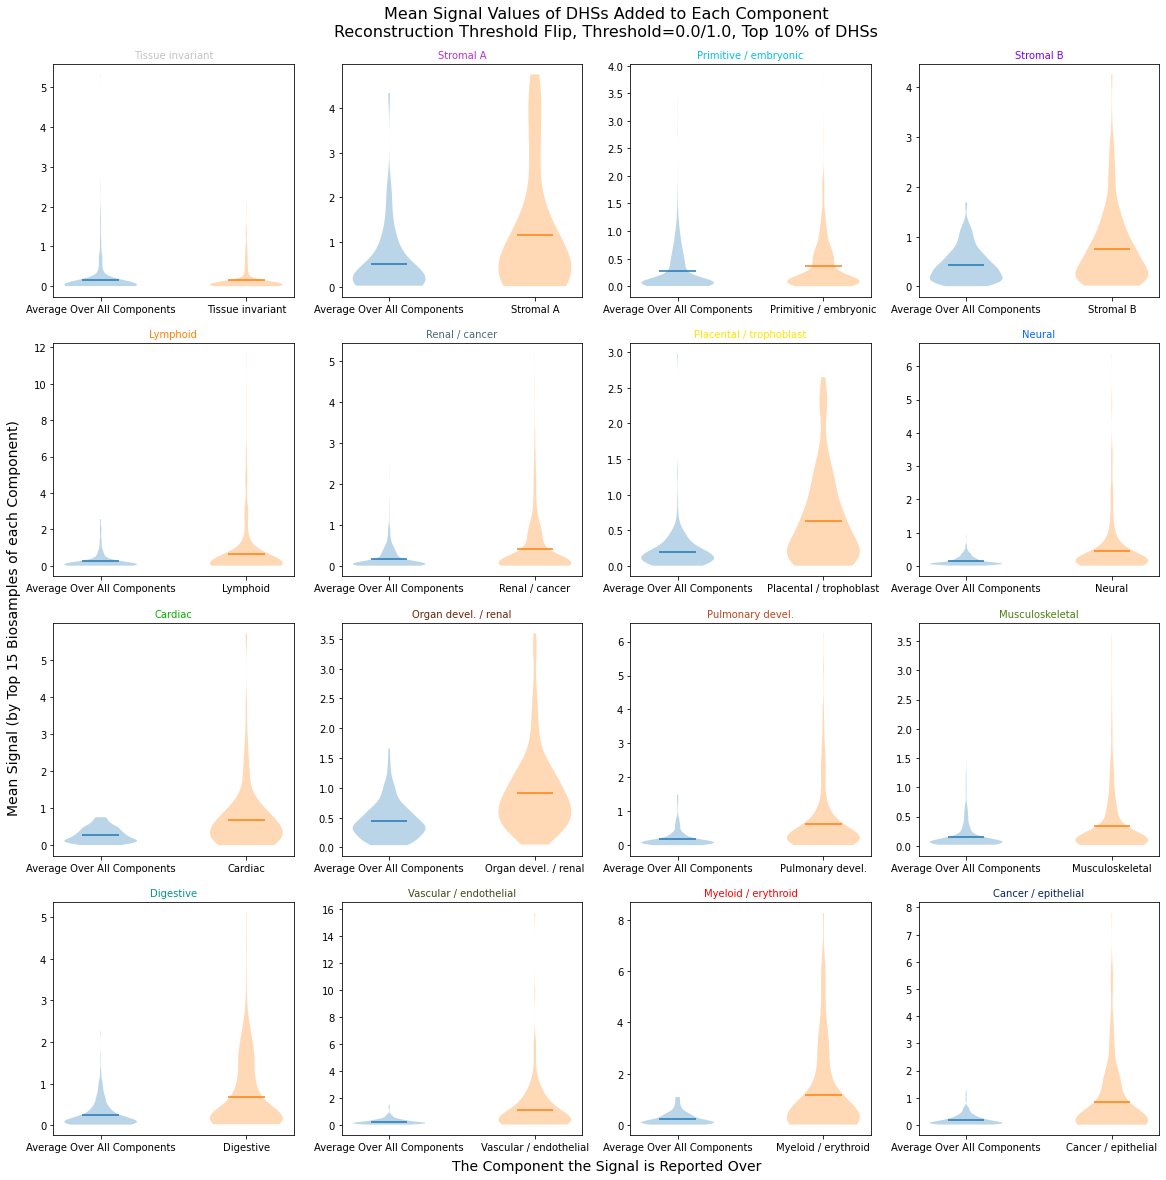

In [65]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(added_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(added_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', comps_for_heatmap[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Added to Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [63]:
original_dhss_average_over_all_comps = []
original_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_original_to_comp = np.where(original_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_original_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    original_dhss_average_over_all_comps.append(np.array(DHS_signal_values_df['average over all comps']))
    original_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of DHSs Originally in Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

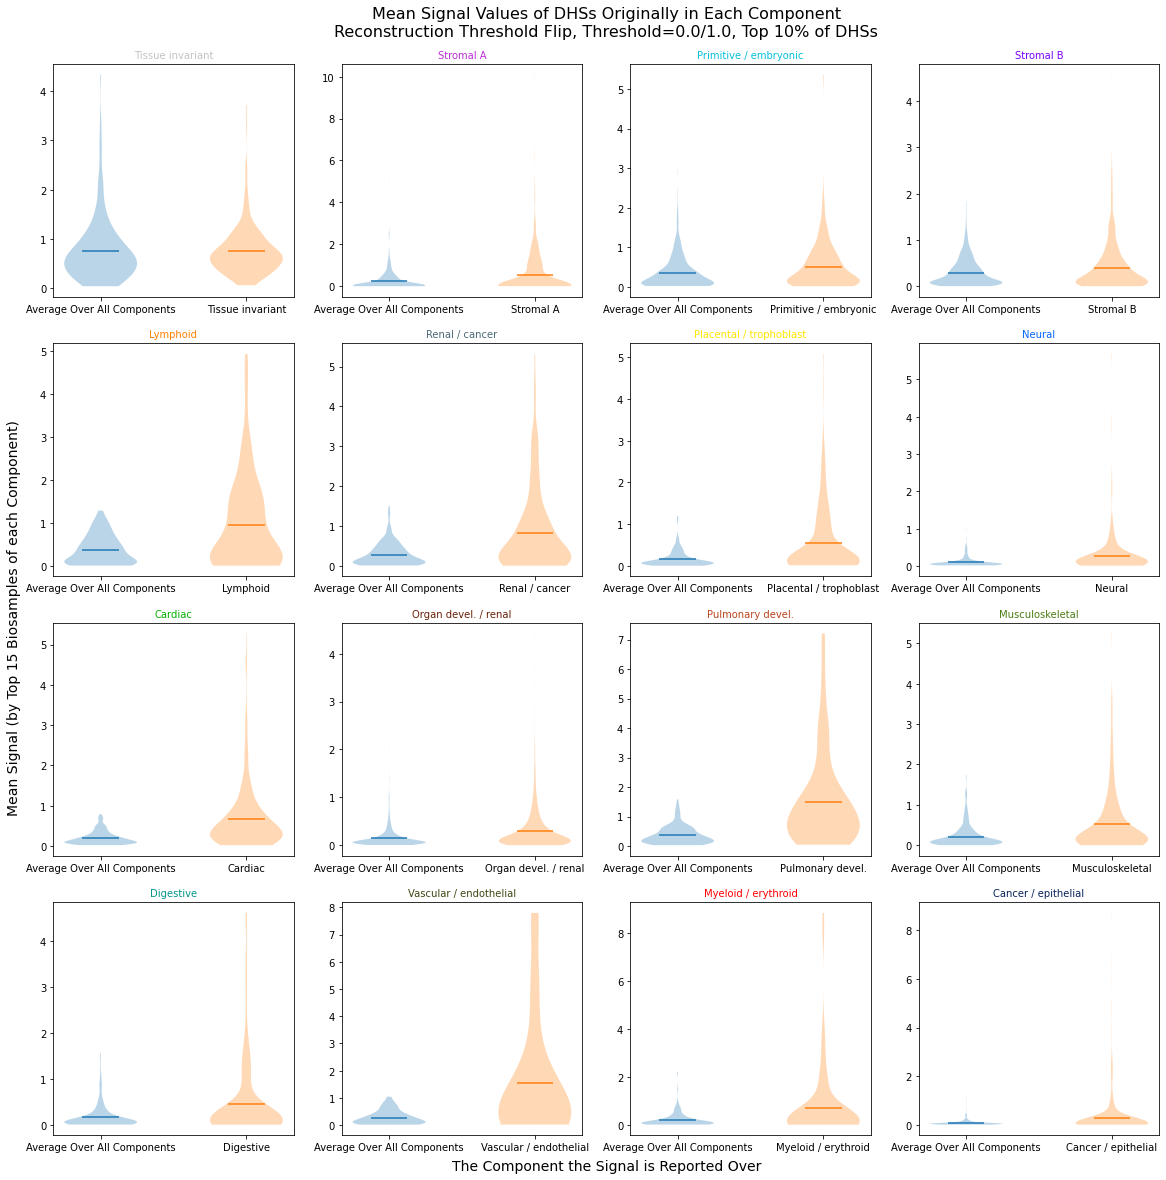

In [64]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(16,16))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(original_dhss_average_over_all_comps[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(original_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
#     ax.set_ylim([0, 10])
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
#     ax.legend(handles, ['Average Over All Components', nmf_comps[ind]])
#     ax.legend(['All Components Averaged', 'All Components Mean', nmf_comps[ind], nmf_comps[ind]+' Mean'])
#     ax.set_xticks([])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Average Over All Components', comps_for_heatmap[ind]])




fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of DHSs Originally in Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [14]:
added_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_added_to_comp = np.where(new_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_added_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    added_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))
    
original_dhss_comp_specific_mean_signal = []
for i in range(16):
    local_inds_original_to_comp = np.where(original_comps==i)[0]
    DHSs = DHSs_changing_component_identifiers[local_inds_original_to_comp]
    DHS_signal_values_df = all_comps_average_signal.loc[DHSs]
    original_dhss_comp_specific_mean_signal.append(np.array(DHS_signal_values_df['comp' + str(i) + ' mean']))

Text(0.5, 1.03, 'Mean Signal Values of Reassigned DHSs of Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs')

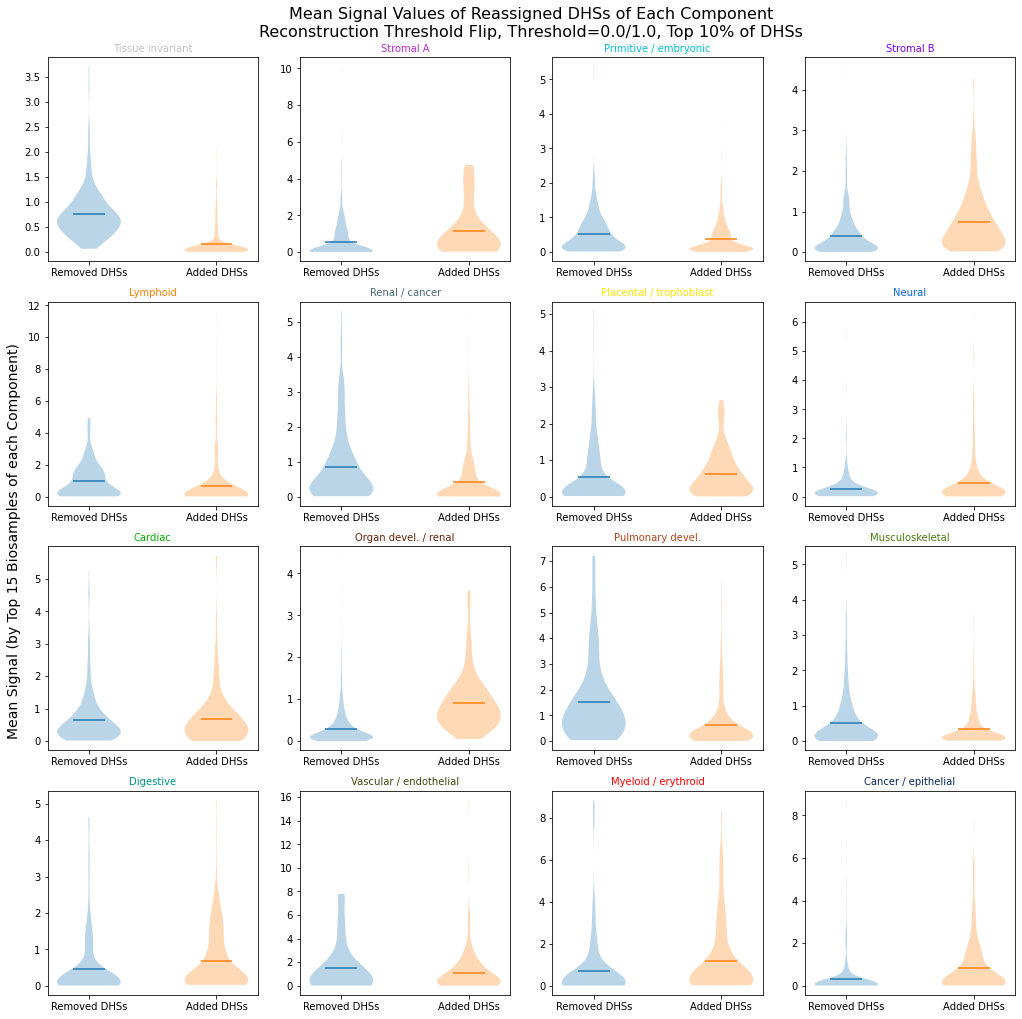

In [30]:
fig, axes = plt.subplots(nrows=4, ncols=4, figsize=(14,14))
# fig.tight_layout()
plt.subplots_adjust(left=0.02, bottom=0.05, right=0.98, top=0.98, wspace=0.2, hspace=0.2)
fig.patch.set_facecolor('white')

violin_colors = ['#1f77b4', '#ff7f0e']
handles = list(plt.Rectangle((0,0),1,1, color=c, alpha=0.5) for c in violin_colors)

axes = axes.ravel()

for ax, ind in zip(axes, range(16)):
    ax.violinplot(original_dhss_comp_specific_mean_signal[ind], positions=[0], showextrema=False, showmeans=True)
    ax.violinplot(added_dhss_comp_specific_mean_signal[ind], positions=[1], showextrema=False, showmeans=True)
    ax.set_title(comps_for_heatmap[ind], fontsize=10, color=color[ind])
    ax.set_xticks([0, 1])
    ax.set_xticklabels(['Removed DHSs', 'Added DHSs'])

# fig.text(0.5, 0.02, 'The Component the Signal is Reported Over', ha='center', fontsize=14)
fig.text(-0.02, 0.5, 'Mean Signal (by Top 15 Biosamples of each Component)', va='center', rotation='vertical', fontsize=14)
plt.suptitle('Mean Signal Values of Reassigned DHSs of Each Component\nReconstruction Threshold Flip, Threshold=0.0/1.0, Top 10% of DHSs', fontsize=16, x=0.5, y=1.03)

In [21]:
heatmap_mixture_all_cycles_top_comp_comparison = np.zeros((1, 16,16), dtype=int)

changed_dhss_all_cycles = []
changed_dhss_original_comp = []
changed_dhss_new_comp = []
changed_dhss_original_comp_val = []
changed_dhss_new_comp_val = []

for i in range(1):
    changed_dhss_1_cycle = []
    original_comp = []
    new_comp = []
    original_comp_val = []
    new_comp_val = []
    
    for comp1, comp0, dhs in zip(mixture_all_cycles_top_comp[i+1], 
                                             mixture_all_cycles_top_comp[i], 
                                             range(len(mixture_all_cycles_top_comp[0]))):
        if ((comp1!=comp0) and (~np.isnan(comp0)) and (~np.isnan(comp1))):
            comp0 = comp0.astype(int)
            comp1 = comp1.astype(int)
            heatmap_mixture_all_cycles_top_comp_comparison[i, comp1, comp0] += 1
            changed_dhss_1_cycle.append(dhs)
            original_comp.append(comp0)
            new_comp.append(comp1)
            
    changed_dhss_all_cycles.append(np.array(changed_dhss_1_cycle))
    changed_dhss_original_comp.append(np.array(original_comp))
    changed_dhss_new_comp.append(np.array(new_comp))

In [22]:
changed_all_dhss_all_cycles_arr = []
for i in changed_all_dhss_all_cycles:
    changed_all_dhss_all_cycles_arr.extend(i)
changed_all_dhss_all_cycles_arr = np.array(changed_all_dhss_all_cycles_arr)
    
changed_dhss_original_comp_arr = []
for i in changed_dhss_original_comp:
    changed_dhss_original_comp_arr.extend(i)
changed_dhss_original_comp_arr = np.array(changed_dhss_original_comp_arr)
    
changed_dhss_new_comp_arr = []
for i in changed_dhss_new_comp:
    changed_dhss_new_comp_arr.extend(i)
changed_dhss_new_comp_arr = np.array(changed_dhss_new_comp_arr)

In [23]:
heatmap_mixture_all_cycles_top_comp_comparison_sum = np.sum(heatmap_mixture_all_cycles_top_comp_comparison, axis=0)

In [24]:
np.sum(heatmap_mixture_all_cycles_top_comp_comparison_sum)

5767

Text(0.5, 1.0, 'Comparing Changed DHS Top Components of Original and New NMF Mixtures\nReconstruction Threshold Flip, Threshold=0.0/1.0')

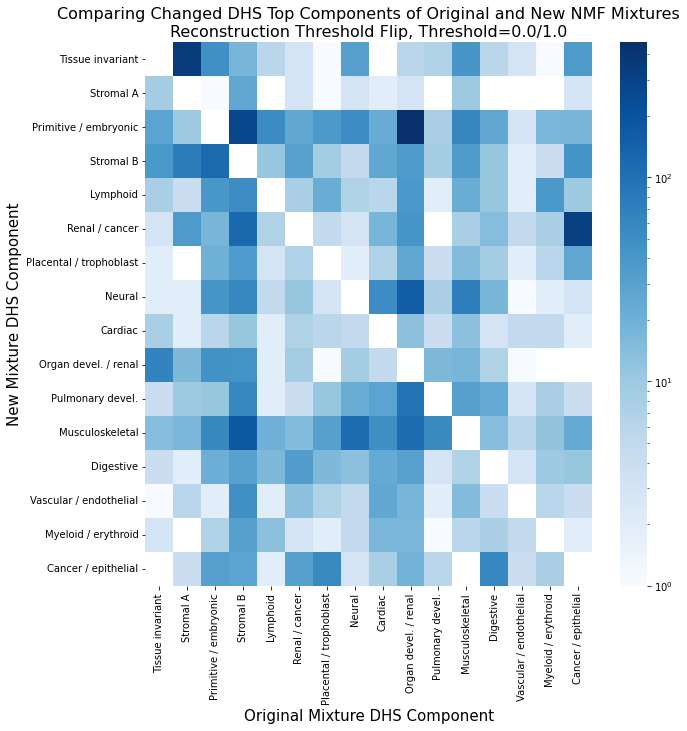

In [28]:
#in plots, yaxis is newest cycle, xaxis is previous cycle
comps_for_heatmap = ['Tissue invariant','Stromal A', 'Primitive / embryonic', 'Stromal B', 'Lymphoid', 'Renal / cancer', 'Placental / trophoblast', 'Neural', 'Cardiac', 'Organ devel. / renal', 'Pulmonary devel.', 'Musculoskeletal', 'Digestive', 'Vascular / endothelial', 'Myeloid / erythroid', 'Cancer / epithelial']

fig = plt.figure(figsize=(10,10))
fig.patch.set_facecolor('white')
ax = sns.heatmap(heatmap_mixture_all_cycles_top_comp_comparison_sum, cmap='Blues', cbar=True, xticklabels=comps_for_heatmap, yticklabels=comps_for_heatmap, norm=LogNorm()) # 
ax.set_ylabel('New Mixture DHS Component', fontsize=15)
ax.set_xlabel('Original Mixture DHS Component', fontsize=15)
ax.set_title('Comparing Changed DHS Top Components of Original and New NMF Mixtures\nReconstruction Threshold Flip, Threshold=0.0/1.0', fontsize=16)